# ARIMA — Modeloplossing (week 4)

Dit is de modeloplossing van het checkpoint. **Wijzig de bestandsnaam of locatie niet**:
de checks (`checks/test_week04.py`) verwijzen naar
`week04/arima_checkpoint_opgave.ipynb`; dit notebook heeft dezelfde celstructuur.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from math import sqrt
from datetime import datetime
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

def evaluate_arima_model(X, arima_order):
    """Walk-forward validatie: RMSE van een ARIMA(order) op reeks X (66/34-split)."""
    X = np.asarray(X, dtype="float32").ravel()
    train_size = int(len(X) * 0.66)
    train, test = X[0:train_size], X[train_size:]
    history = [x for x in train]
    predictions = list()
    for t in range(len(test)):
        model = ARIMA(history, order=arima_order)
        model_fit = model.fit()
        predictions.append(model_fit.forecast()[0])
        history.append(test[t])
    return sqrt(mean_squared_error(test, predictions))

def grid_search_arima(X, p_values, d_values, q_values):
    """Zoekt beste (p,d,q) via walk-forward RMSE. Geeft (best_order, best_rmse)."""
    best_score, best_cfg = float("inf"), None
    for p in p_values:
        for d in d_values:
            for q in q_values:
                try:
                    rmse = evaluate_arima_model(X, (p, d, q))
                except Exception:
                    continue
                if rmse < best_score:
                    best_score, best_cfg = rmse, (p, d, q)
    return best_cfg, best_score

p_values = [0, 1, 2, 4]
d_values = [0, 1]
q_values = [0, 1]


## Oefening 1 — TF_BIRTHS (geboortecijfers België)

1. Laad `./data/TF_BIRTHS.csv` in (scheidingsteken `;`) en hernoem de kolom
   `MS_NUM_BIRTHS` naar `value`. Parse de eerste kolom (`DT_DATE`, formaat
   `%d/%m/%Y`) als index. Sla op in **`series_births`** (DataFrame).
2. Maak **`births_2022_daily`**: enkel de dagcijfers van 2022. Maak een plot en
   bekijk het histogram van de dagcijfers — wat valt op? (tip: kijk naar weekdagen
   vs weekend → de dagcijfers zijn bimodaal)
3. Maak **`monthly_births`**: de volledige reeks hersamplet naar maanden (som).
   Welk seizoenspatroon zie je? (beantwoord de meerkeuzevraag verderop)
4. Test met de ADF-test of de maandreeks stationair is.
5. Zoek met grid search de beste ARIMA-parameters voor de maandreeks en sla op in
   **`best_order_births`** (tuple) en de bijhorende walk-forward RMSE in
   **`rmse_births`**.
6. Fit het finale model en plot de residuals.


In [3]:
# 1. data inladen; eerste kolom als datum-index
series_births = pd.read_csv('../data/TF_BIRTHS.csv', header=0, sep=';')
series_births.index = pd.to_datetime(series_births['DT_DATE'], format='%d/%m/%Y')
series_births = series_births.drop(columns=['DT_DATE'])
series_births = series_births.rename(columns={'MS_NUM_BIRTHS': 'value'})
print(series_births.head())


            value
DT_DATE          
1992-01-01    219
1992-01-02    331
1992-01-03    420
1992-01-04    282
1992-01-05    252


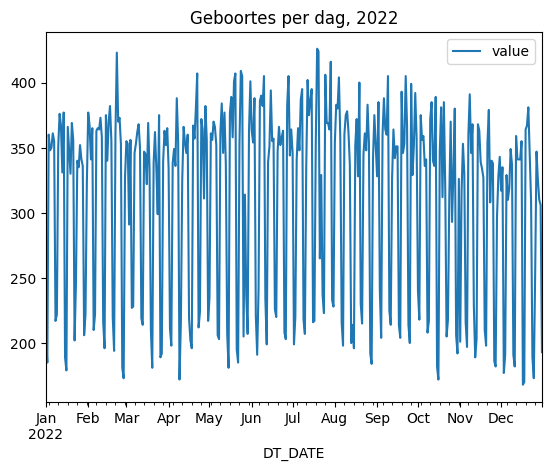

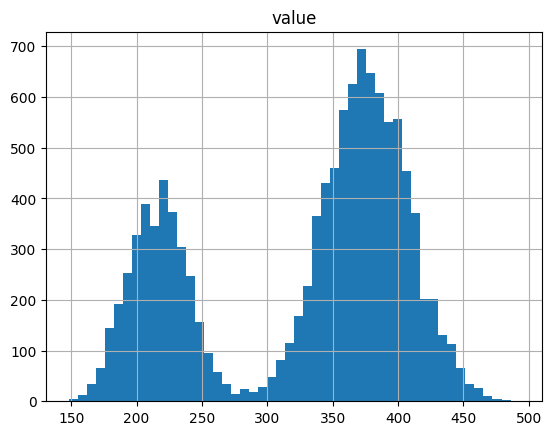

In [4]:
# 2. dagcijfers 2022 + histogram (bimodaal: weekdagen vs weekend)
births_2022_daily = series_births.loc['2022-01-01':'2022-12-31']
births_2022_daily.plot(title='Geboortes per dag, 2022')
plt.show()

series_births.hist(bins=50)
plt.show()


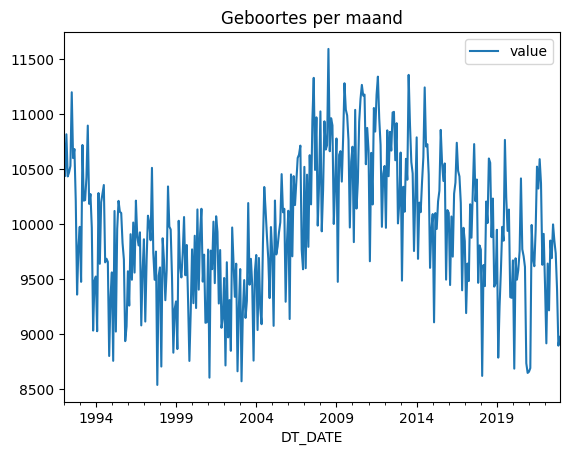

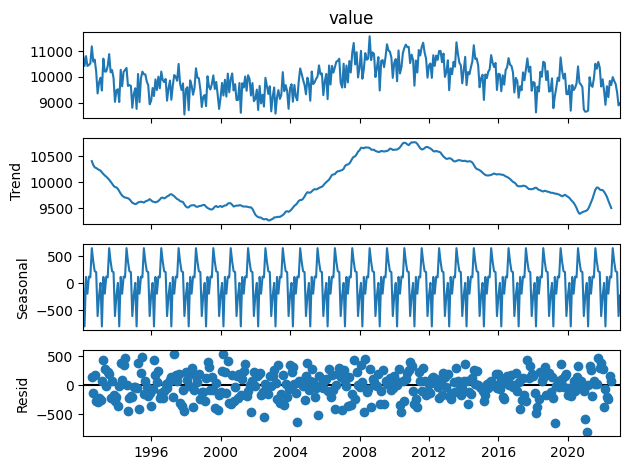

In [5]:
# 3. maandcijfers
monthly_births = series_births.resample('ME').sum()
monthly_births.plot(title='Geboortes per maand')
plt.show()

from statsmodels.tsa.seasonal import seasonal_decompose
seasonal_decompose(monthly_births['value'], model='additive').plot()
plt.show()


In [6]:
# 4. is de maandreeks stationair?
result = adfuller(monthly_births['value'].dropna())
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])


ADF statistiek: -1.219986
p-waarde: 0.664940


In [7]:
# 5. grid search op de maandreeks
best_order_births, rmse_births = grid_search_arima(monthly_births['value'], p_values, d_values, q_values)
print('Best ARIMA%s RMSE=%.3f' % (best_order_births, rmse_births))


Best ARIMA(4, 1, 1) RMSE=414.456


                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  372
Model:                 ARIMA(4, 1, 1)   Log Likelihood               -2771.191
Date:                Sun, 11 Oct 2026   AIC                           5554.381
Time:                        13:41:48   BIC                           5577.878
Sample:                    01-31-1992   HQIC                          5563.713
                         - 12-31-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2137      0.057      3.754      0.000       0.102       0.325
ar.L2          0.2884      0.059      4.905      0.000       0.173       0.404
ar.L3          0.1097      0.045      2.428      0.0

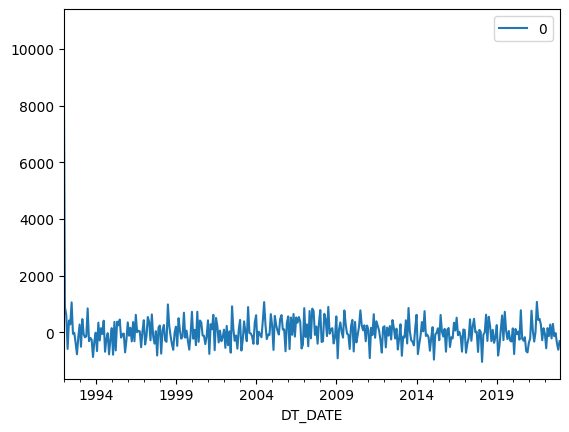

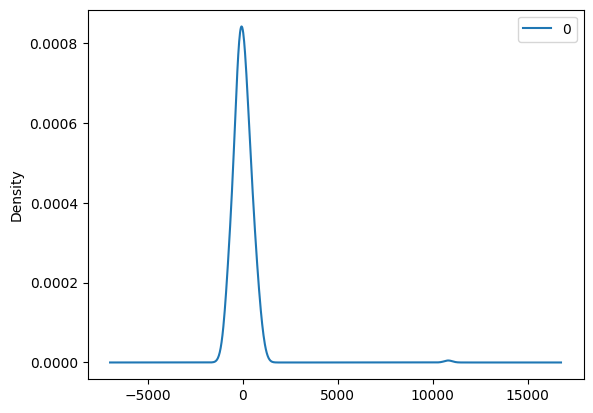

In [8]:
# 6. finaal model en residuals
model_births = ARIMA(monthly_births['value'], order=best_order_births)
model_fit_births = model_births.fit()
print(model_fit_births.summary())

residuals_births = pd.DataFrame(model_fit_births.resid)
residuals_births.plot()
residuals_births.plot(kind='kde')
plt.show()


## Oefening 2 — AQI: luchtkwaliteit Duitsland

1. Laad `./data/data_date.csv` in (eerste kolom = datum-index).
2. Filter op `Country == 'Germany'` en hou enkel de kolom `AQI Value` (hernoemd naar
   `value`). Sla op in **`aqi_germany`**.
3. Filter de data tussen 21 juli 2022 en 22 september 2022 → **`aqi_filtered`**.
4. Test met de ADF-test of de reeks stationair is (beantwoord daarna de
   meerkeuzevraag `antwoord_adf`).
5. Grid search → **`best_order_aqi`** en **`rmse_aqi`**. Fit het finale model en
   plot de residuals.


In [9]:
# 1. data inladen
aqi = pd.read_csv('../data/data_date.csv', header=0, index_col=0, parse_dates=[0])
print(aqi.head())


              Country                          Status  AQI Value
Date                                                            
2022-07-21    Albania                            Good         14
2022-07-21    Algeria                        Moderate         65
2022-07-21    Andorra                        Moderate         55
2022-07-21     Angola  Unhealthy for Sensitive Groups        113
2022-07-21  Argentina                        Moderate         63


In [10]:
# 2. enkel Duitsland, enkel de AQI-waarde
aqi_germany = aqi[aqi['Country'] == 'Germany'][['AQI Value']]
aqi_germany = aqi_germany.rename(columns={'AQI Value': 'value'})
aqi_germany.head()


,value
Date,
2022-07-21,77
2022-07-21,79
2022-07-22,58
2022-07-22,61
2022-07-22,66


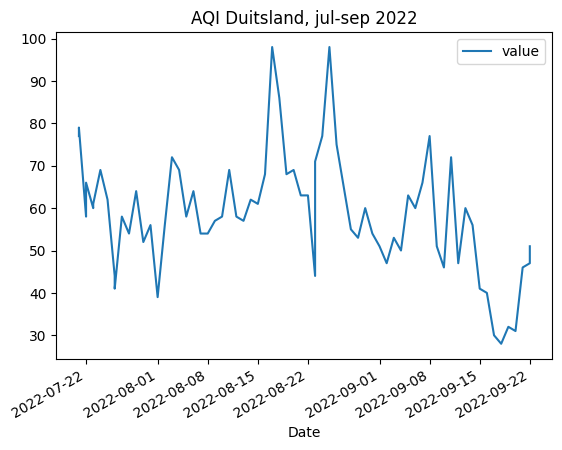

In [11]:
# 3. datumfilter
aqi_filtered = aqi_germany.loc['2022-07-21':'2022-09-22']
aqi_filtered.plot(title='AQI Duitsland, jul-sep 2022')
plt.show()


In [12]:
# 4. stationariteit
result = adfuller(aqi_filtered['value'].dropna())
print('ADF statistiek: %f' % result[0])
print('p-waarde: %f' % result[1])


ADF statistiek: -4.119410
p-waarde: 0.000899


Best ARIMA(0, 1, 1) RMSE=10.759


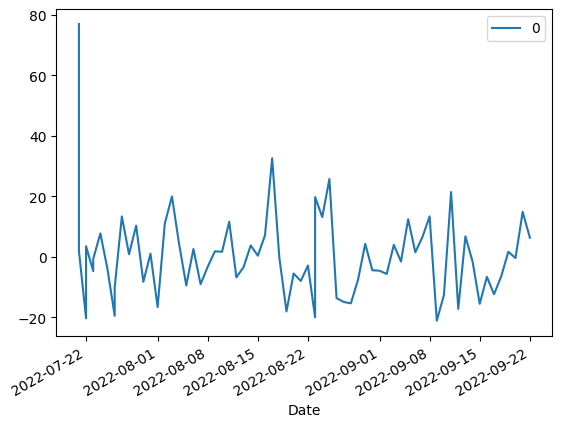

In [13]:
# 5. grid search + finaal model
best_order_aqi, rmse_aqi = grid_search_arima(aqi_filtered['value'], p_values, d_values, q_values)
print('Best ARIMA%s RMSE=%.3f' % (best_order_aqi, rmse_aqi))

model_aqi = ARIMA(aqi_filtered['value'], order=best_order_aqi)
model_fit_aqi = model_aqi.fit()
residuals_aqi = pd.DataFrame(model_fit_aqi.resid)
residuals_aqi.plot()
plt.show()


## Oefening 3 — Electric Production

1. Laad `./data/Electric_Production.xls` in (het is effectief een CSV; eerste kolom =
   datum-index) en hernoem `Value` naar `value` → **`series_electric`**.
2. Bekijk de reeks: hier is duidelijk een trend én een seizoenspatroon, dus `d = 1`
   is een goede keuze voor de differencing.
3. Grid search → **`best_order_electric`** en **`rmse_electric`**. Fit het finale
   model en plot walk-forward voorspellingen tegen de testset.


In [15]:
# 1. data inladen (bestand is effectief CSV ondanks de .xls-extensie)
series_electric = pd.read_csv('../data/Electric_Production.xls', header=0, index_col=0, parse_dates=[0])
series_electric = series_electric.rename(columns={'Value': 'value'})
print(series_electric.head())


              value
DATE               
1985-01-01  72.5052
1985-02-01  70.6720
1985-03-01  62.4502
1985-04-01  57.4714
1985-05-01  55.3151


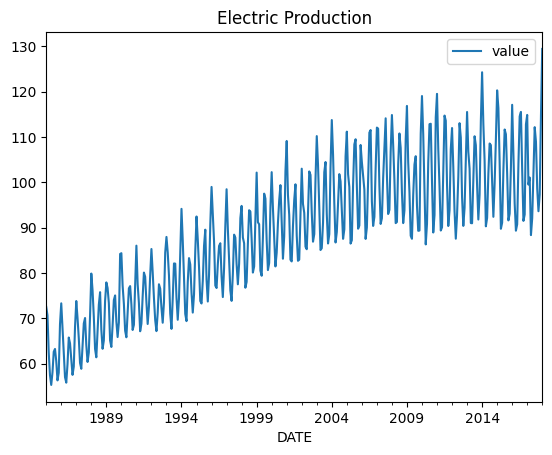

In [16]:
# 2. plot
series_electric.plot(title='Electric Production')
plt.show()


In [17]:
# 3. grid search
best_order_electric, rmse_electric = grid_search_arima(series_electric['value'], p_values, d_values, q_values)
print('Best ARIMA%s RMSE=%.3f' % (best_order_electric, rmse_electric))


Best ARIMA(4, 1, 1) RMSE=4.399


Test RMSE walk-forward: 4.399


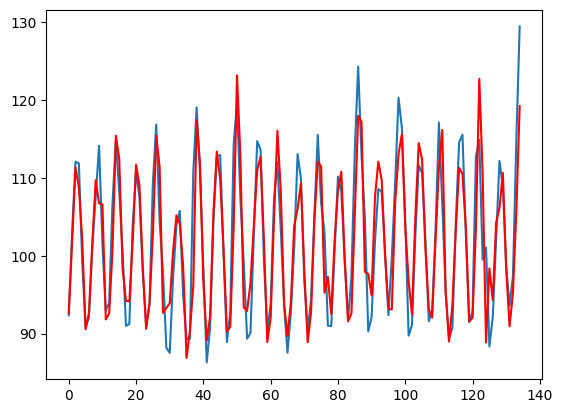

In [18]:
# finaal model + walk-forward voorspellingen tegen de testset
X_electric = series_electric['value'].values.astype('float32').ravel()
size = int(len(X_electric) * 0.66)
train_electric, test_electric = X_electric[0:size], X_electric[size:]
history = [x for x in train_electric]
predictions = list()
for t in range(len(test_electric)):
    model = ARIMA(history, order=best_order_electric)
    model_fit = model.fit()
    predictions.append(model_fit.forecast()[0])
    history.append(test_electric[t])

rmse_wf = sqrt(mean_squared_error(test_electric, predictions))
print('Test RMSE walk-forward: %.3f' % rmse_wf)

plt.plot(test_electric)
plt.plot(predictions, color='red')
plt.show()


## Meerkeuzevragen

**Vraag 1 (ADF):** de p-waarde van de ADF-test op de gefilterde AQI-reeks van Duitsland
is kleiner dan 0.05. Wat betekent dit?

- A) De reeks is niet-stationair; er is differencing nodig
- B) De reeks is stationair; differencing is niet nodig
- C) De reeks heeft een sterke trend
- D) De ADF-test zegt niets over stationariteit

**Vraag 2 (seizoen geboortes):** welk seizoenspatroon zie je in de maandelijkse
geboortecijfers van België?

- A) Geen enkel seizoenspatroon
- B) Een piek rond juli-september
- C) Enkel een piek in december
- D) Een lineair dalende trend zonder seizoenen


In [19]:
antwoord_adf = "B"

In [20]:
antwoord_seizoen_births = "B"